In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [62]:
# Random seed
SEED = 42
rng = np.random.default_rng(SEED)

# True function
f = lambda x: np.sin(2 * np.pi * x)

# Generate data
def make_data(n):
    x = rng.uniform(0, 1, n)
    y = f(x) + rng.normal(0, 0.3, n)

    return x.reshape(-1, 1), y

# Polynomial model
def poly(degree):
    return make_pipeline(
        PolynomialFeatures(degree),
        LinearRegression()
    )

In [63]:
# Training data
X_train, y_train = make_data(30)

# Test data
X_test, y_test = make_data(1000)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

Training shape: (30, 1)
Test shape: (1000, 1)


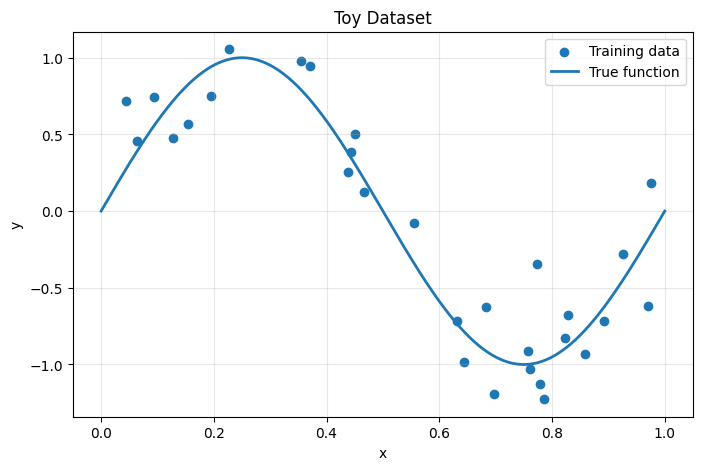

In [64]:
# Smooth true curve
x_plot = np.linspace(0, 1, 500)
y_true = f(x_plot)

plt.figure(figsize=(8, 5))

plt.scatter(
    X_train,
    y_train,
    label="Training data"
)

plt.plot(
    x_plot,
    y_true,
    linewidth=2,
    label="True function"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Toy Dataset")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [65]:
results = []

for degree in range(1, 13):

    # Create model
    model = poly(degree)

    # Train
    model.fit(X_train, y_train)

    # Predictions on training data
    train_pred = model.predict(X_train)

    # Predictions on test data
    test_pred = model.predict(X_test)

    # Calculate errors
    train_mse = mean_squared_error(y_train, train_pred)
    test_mse = mean_squared_error(y_test, test_pred)

    results.append([
        degree,
        train_mse,
        test_mse
    ])

results_df = pd.DataFrame(
    results,
    columns=["Degree", "Training MSE", "Test MSE"]
)

print(results_df.round(4))

    Degree  Training MSE  Test MSE
0        1        0.2062    0.2935
1        2        0.2019    0.2955
2        3        0.0638    0.1024
3        4        0.0611    0.1105
4        5        0.0473    0.1218
5        6        0.0448    0.1435
6        7        0.0447    0.1399
7        8        0.0446    0.1297
8        9        0.0438    0.1134
9       10        0.0436    0.1114
10      11        0.0429    0.1448
11      12        0.0363    1.7467


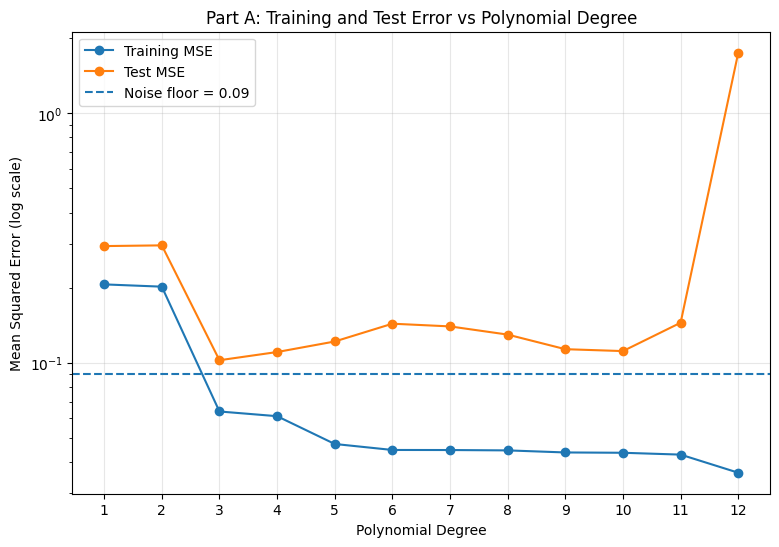

In [66]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    results_df["Degree"],
    results_df["Training MSE"],
    marker="o",
    label="Training MSE"
)

plt.semilogy(
    results_df["Degree"],
    results_df["Test MSE"],
    marker="o",
    label="Test MSE"
)

# Noise floor
plt.axhline(
    0.3**2,
    linestyle="--",
    label="Noise floor = 0.09"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (log scale)")
plt.title("Part A: Training and Test Error vs Polynomial Degree")

plt.xticks(range(1, 13))

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [67]:
average_results = []

for degree in range(1, 13):

    train_errors = []
    test_errors = []

    for repeat in range(50):

        # New training dataset
        X_train_new, y_train_new = make_data(30)

        # New model
        model = poly(degree)

        # Train
        model.fit(X_train_new, y_train_new)

        # Training error
        train_pred = model.predict(X_train_new)

        train_mse = mean_squared_error(
            y_train_new,
            train_pred
        )

        # Test error
        test_pred = model.predict(X_test)

        test_mse = mean_squared_error(
            y_test,
            test_pred
        )

        train_errors.append(train_mse)
        test_errors.append(test_mse)

    # Average over 50 training sets
    average_results.append([
        degree,
        np.mean(train_errors),
        np.mean(test_errors)
    ])

average_df = pd.DataFrame(
    average_results,
    columns=[
        "Degree",
        "Average Training MSE",
        "Average Test MSE"
    ]
)

print(average_df.round(4))

    Degree  Average Training MSE  Average Test MSE
0        1                0.2574            0.3218
1        2                0.2619            0.3344
2        3                0.0812            0.1136
3        4                0.0774            0.1422
4        5                0.0718            0.1327
5        6                0.0697            0.1770
6        7                0.0685            0.3279
7        8                0.0602            0.4944
8        9                0.0600           10.0022
9       10                0.0611           11.4816
10      11                0.0539          194.3099
11      12                0.0497        10627.5839


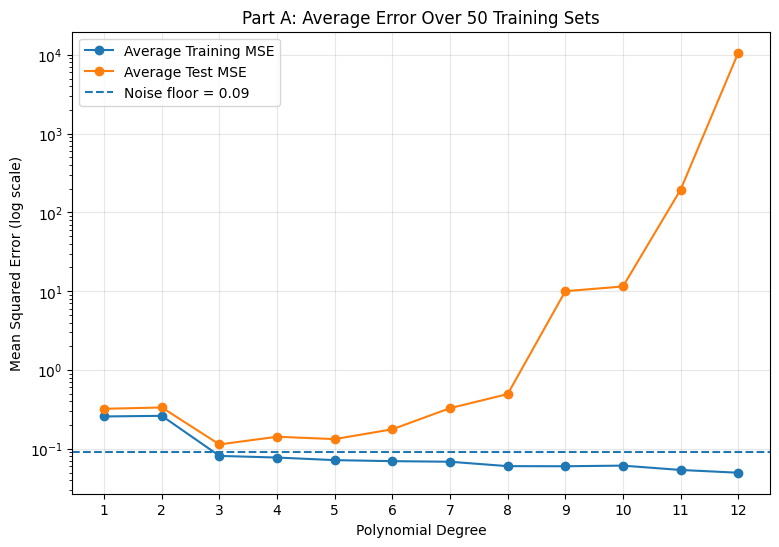

In [68]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    average_df["Degree"],
    average_df["Average Training MSE"],
    marker="o",
    label="Average Training MSE"
)

plt.semilogy(
    average_df["Degree"],
    average_df["Average Test MSE"],
    marker="o",
    label="Average Test MSE"
)

plt.axhline(
    0.09,
    linestyle="--",
    label="Noise floor = 0.09"
)

plt.xlabel("Polynomial Degree")
plt.ylabel("Mean Squared Error (log scale)")
plt.title("Part A: Average Error Over 50 Training Sets")

plt.xticks(range(1, 13))

plt.legend()
plt.grid(alpha=0.3)

plt.show()

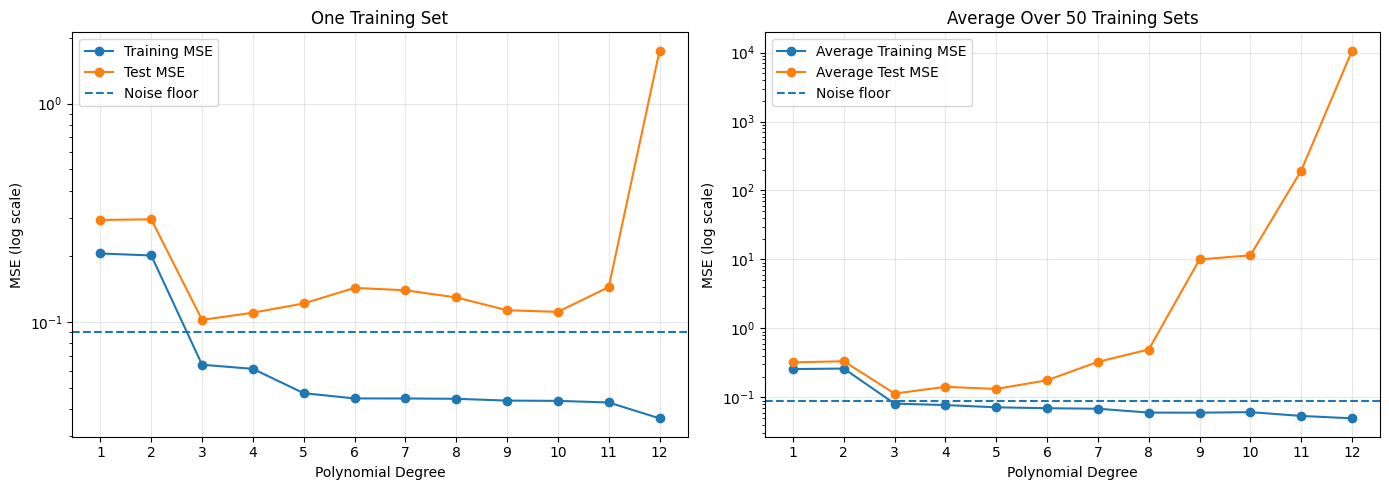

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Single run
axes[0].semilogy(
    results_df["Degree"],
    results_df["Training MSE"],
    marker="o",
    label="Training MSE"
)

axes[0].semilogy(
    results_df["Degree"],
    results_df["Test MSE"],
    marker="o",
    label="Test MSE"
)

axes[0].axhline(
    0.09,
    linestyle="--",
    label="Noise floor"
)

axes[0].set_title("One Training Set")
axes[0].set_xlabel("Polynomial Degree")
axes[0].set_ylabel("MSE (log scale)")
axes[0].set_xticks(range(1, 13))
axes[0].legend()
axes[0].grid(alpha=0.3)


# 50 training sets
axes[1].semilogy(
    average_df["Degree"],
    average_df["Average Training MSE"],
    marker="o",
    label="Average Training MSE"
)

axes[1].semilogy(
    average_df["Degree"],
    average_df["Average Test MSE"],
    marker="o",
    label="Average Test MSE"
)

axes[1].axhline(
    0.09,
    linestyle="--",
    label="Noise floor"
)

axes[1].set_title("Average Over 50 Training Sets")
axes[1].set_xlabel("Polynomial Degree")
axes[1].set_ylabel("MSE (log scale)")
axes[1].set_xticks(range(1, 13))
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [70]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = []

for degree in range(1, 13):

    model = poly(degree)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error"
    )

    cv_mse = -scores.mean()

    cv_results.append([
        degree,
        cv_mse
    ])

cv_df = pd.DataFrame(
    cv_results,
    columns=["Degree", "CV MSE"]
)

print(cv_df.round(4))

chosen_degree = cv_df.loc[
    cv_df["CV MSE"].idxmin(),
    "Degree"
]

print("Chosen degree:", int(chosen_degree))



    Degree     CV MSE
0        1     0.2779
1        2     0.4542
2        3     0.0758
3        4     0.1350
4        5     0.1312
5        6     0.1385
6        7     0.2863
7        8     2.4054
8        9     0.1880
9       10     6.6435
10      11   656.6014
11      12  1357.4039
Chosen degree: 3


Grid shape: (100, 1)
True values shape: (100,)


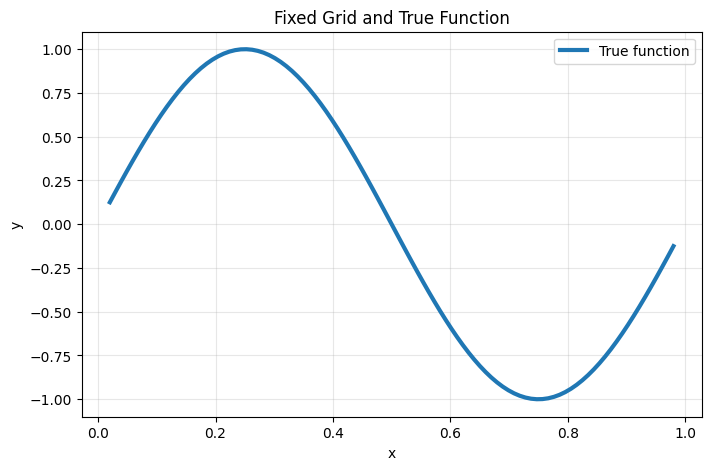

In [71]:
# ============================================================
# PART B
# Measure Bias and Variance Directly
# ============================================================

# Fixed grid of x values
x_grid = np.linspace(0.02, 0.98, 100).reshape(-1, 1)

# True values on this grid
true_values = f(x_grid.ravel())

print("Grid shape:", x_grid.shape)
print("True values shape:", true_values.shape)
plt.figure(figsize=(8, 5))

plt.plot(
    x_grid,
    true_values,
    linewidth=3,
    label="True function"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Fixed Grid and True Function")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [72]:
degrees = [1, 3, 9]

n_training = 300
n_repeats = 200

In [73]:
# ============================================================
# Generate predictions from 200 different training sets
# ============================================================

degrees = [1, 3, 9]
n_training = 300
n_repeats = 200

all_predictions = {}

for degree in degrees:

    predictions = []

    for i in range(n_repeats):

        # Create a NEW training set
        X_train_b, y_train_b = make_data(n_training)

        # Create polynomial model
        model = poly(degree)

        # Train model
        model.fit(
            X_train_b,
            y_train_b
        )

        # Predict on the SAME fixed grid
        grid_predictions = model.predict(x_grid)

        predictions.append(grid_predictions)

    # Convert to numpy array
    predictions = np.array(predictions)

    all_predictions[degree] = predictions

    print(
        f"Degree {degree}:",
        predictions.shape
    )

Degree 1: (200, 100)
Degree 3: (200, 100)
Degree 9: (200, 100)


In [74]:
bias_variance_results = []

for degree in degrees:

    predictions = all_predictions[degree]

    # Mean prediction at every x
    mean_prediction = np.mean(
        predictions,
        axis=0
    )

    # Bias squared at every x
    bias_squared_each_x = (
        mean_prediction - true_values
    ) ** 2

    # Average across all x values
    bias_squared = np.mean(
        bias_squared_each_x
    )

    print(
        f"Degree {degree}: Bias² = {bias_squared:.6f}"
    )

Degree 1: Bias² = 0.177087
Degree 3: Bias² = 0.003615
Degree 9: Bias² = 0.000011


In [75]:
for degree in degrees:

    predictions = all_predictions[degree]

    # Variance at each x
    variance_each_x = np.var(
        predictions,
        axis=0
    )

    # Average variance across grid
    variance = np.mean(
        variance_each_x
    )

    print(
        f"Degree {degree}: Variance = {variance:.6f}"
    )

Degree 1: Variance = 0.002146
Degree 3: Variance = 0.001256
Degree 9: Variance = 0.002761


In [76]:
# ============================================================
# Calculate Bias Squared and Variance
# ============================================================

bias_variance_results = []

for degree in degrees:

    predictions = all_predictions[degree]

    # --------------------------------------------------------
    # Mean prediction across 200 models
    # --------------------------------------------------------

    mean_prediction = np.mean(
        predictions,
        axis=0
    )

    # --------------------------------------------------------
    # Bias squared
    # --------------------------------------------------------

    bias_squared = np.mean(
        (mean_prediction - true_values) ** 2
    )

    # --------------------------------------------------------
    # Variance
    # --------------------------------------------------------

    variance = np.mean(
        np.var(
            predictions,
            axis=0
        )
    )

    # --------------------------------------------------------
    # Bias² + Variance
    # --------------------------------------------------------

    total = bias_squared + variance

    bias_variance_results.append([
        degree,
        bias_squared,
        variance,
        total
    ])


bias_variance_df = pd.DataFrame(
    bias_variance_results,
    columns=[
        "Degree",
        "Bias Squared",
        "Variance",
        "Bias² + Variance"
    ]
)

print("Part B Results:")
display(
    bias_variance_df.round(4)
)

Part B Results:


,Degree,Bias Squared,Variance,Bias² + Variance
0,1,0.1771,0.0021,0.1792
1,3,0.0036,0.0013,0.0049
2,9,0.0000,0.0028,0.0028


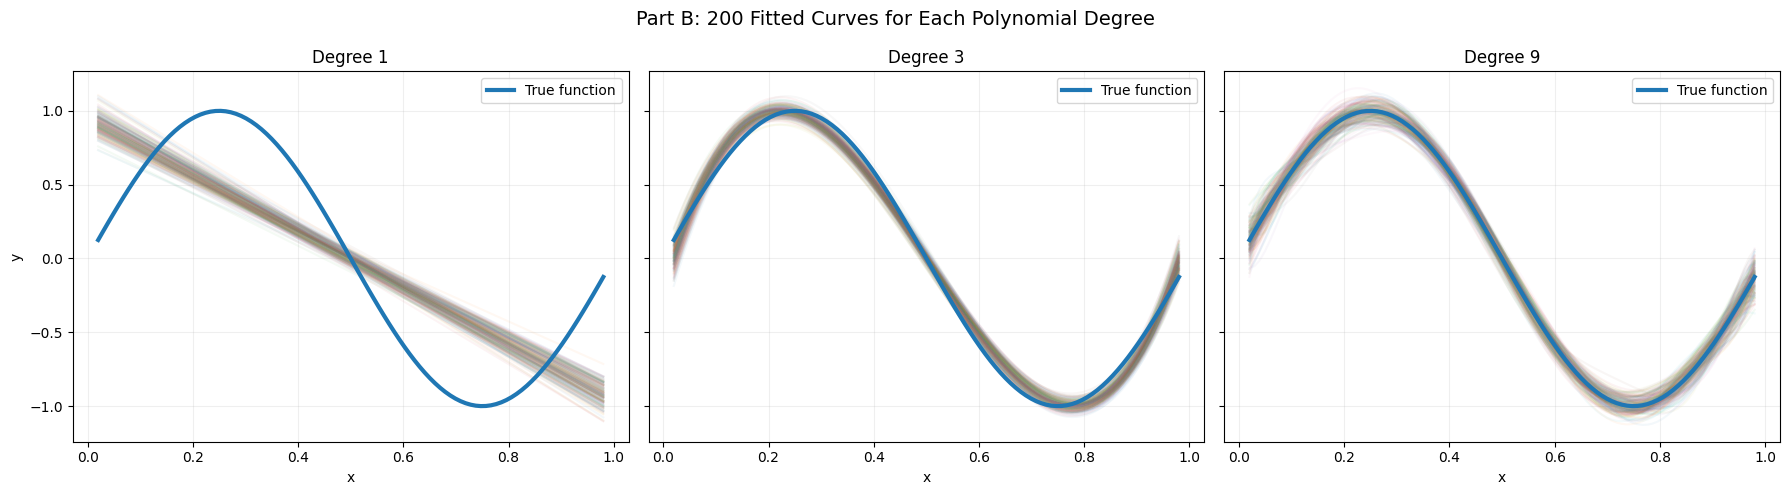

In [77]:
# ============================================================
# Plot 200 fitted curves for each degree
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    sharey=True
)

for ax, degree in zip(axes, degrees):

    predictions = all_predictions[degree]

    # Plot all 200 models lightly
    for i in range(n_repeats):

        ax.plot(
            x_grid.ravel(),
            predictions[i],
            alpha=0.05
        )

    # Plot true function strongly
    ax.plot(
        x_grid.ravel(),
        true_values,
        linewidth=3,
        label="True function"
    )

    ax.set_title(
        f"Degree {degree}"
    )

    ax.set_xlabel("x")

    ax.grid(alpha=0.2)

    ax.legend()


axes[0].set_ylabel("y")

plt.suptitle(
    "Part B: 200 Fitted Curves for Each Polynomial Degree",
    fontsize=14
)

plt.tight_layout()

plt.show()

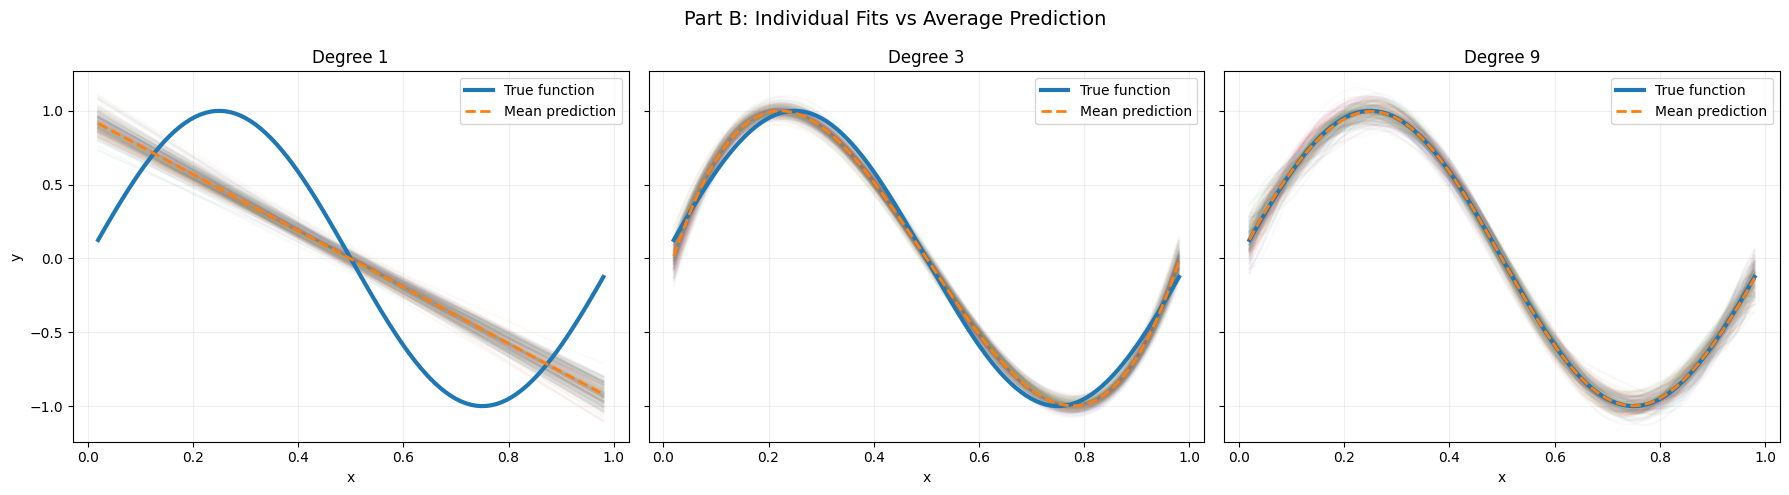

In [78]:
# ============================================================
# Plot average prediction vs true function
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(18, 5),
    sharey=True
)

for ax, degree in zip(axes, degrees):

    predictions = all_predictions[degree]

    # Mean prediction across 200 models
    mean_prediction = np.mean(
        predictions,
        axis=0
    )

    # Plot 200 individual curves lightly
    for i in range(n_repeats):

        ax.plot(
            x_grid.ravel(),
            predictions[i],
            alpha=0.04
        )

    # True function
    ax.plot(
        x_grid.ravel(),
        true_values,
        linewidth=3,
        label="True function"
    )

    # Average model
    ax.plot(
        x_grid.ravel(),
        mean_prediction,
        linewidth=2,
        linestyle="--",
        label="Mean prediction"
    )

    ax.set_title(
        f"Degree {degree}"
    )

    ax.set_xlabel("x")
    ax.grid(alpha=0.2)
    ax.legend()


axes[0].set_ylabel("y")

plt.suptitle(
    "Part B: Individual Fits vs Average Prediction",
    fontsize=14
)

plt.tight_layout()

plt.show()

In [79]:
# ============================================================
# PART D — MINI NO-FREE-LUNCH DEMO
# ============================================================

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error


# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

n_train = 30
n_test = 1000
n_repeats = 100

# We will use the same random generator already used in Parts A-C
# if rng already exists in your notebook.
#
# If your notebook does NOT have rng, uncomment:
# rng = np.random.default_rng(42)


# ------------------------------------------------------------
# TRUE FUNCTIONS
# ------------------------------------------------------------

def d1_function(x):
    # D1: y = 2x
    return 2 * x


def d2_function(x):
    # D2: sine wave from Part A
    return np.sin(2 * np.pi * x)


# ------------------------------------------------------------
# STORE RESULTS
# ------------------------------------------------------------

results = []


# ============================================================
# RUN THE EXPERIMENT
# ============================================================

for repeat in range(n_repeats):

    # --------------------------------------------------------
    # Generate training data
    # --------------------------------------------------------

    x_train = rng.uniform(0, 1, n_train)

    # D1: y = 2x + noise
    y_train_d1 = d1_function(x_train) + rng.normal(
        0, 0.3, n_train
    )

    # D2: sine + noise
    y_train_d2 = d2_function(x_train) + rng.normal(
        0, 0.3, n_train
    )

    # D3: pure noise
    y_train_d3 = rng.normal(
        0, 0.3, n_train
    )


    # --------------------------------------------------------
    # Generate fresh test data
    # --------------------------------------------------------

    x_test = rng.uniform(0, 1, n_test)

    # D1 test data
    y_test_d1 = d1_function(x_test) + rng.normal(
        0, 0.3, n_test
    )

    # D2 test data
    y_test_d2 = d2_function(x_test) + rng.normal(
        0, 0.3, n_test
    )

    # D3 test data: completely unrelated to x
    y_test_d3 = rng.normal(
        0, 0.3, n_test
    )


    # --------------------------------------------------------
    # Define four predictors
    # --------------------------------------------------------

    models = {
        "Linear regression": LinearRegression(),

        "Degree-9 polynomial": make_pipeline(
            PolynomialFeatures(degree=9),
            LinearRegression()
        ),

        "kNN, k=5": KNeighborsRegressor(
            n_neighbors=5
        )
    }


    # --------------------------------------------------------
    # Run all four predictors
    # --------------------------------------------------------

    for model_name, model in models.items():

        # ============================
        # D1
        # ============================

        model.fit(
            x_train.reshape(-1, 1),
            y_train_d1
        )

        prediction_d1 = model.predict(
            x_test.reshape(-1, 1)
        )

        mse_d1 = mean_squared_error(
            y_test_d1,
            prediction_d1
        )


        # ============================
        # D2
        # ============================

        model.fit(
            x_train.reshape(-1, 1),
            y_train_d2
        )

        prediction_d2 = model.predict(
            x_test.reshape(-1, 1)
        )

        mse_d2 = mean_squared_error(
            y_test_d2,
            prediction_d2
        )


        # ============================
        # D3
        # ============================

        model.fit(
            x_train.reshape(-1, 1),
            y_train_d3
        )

        prediction_d3 = model.predict(
            x_test.reshape(-1, 1)
        )

        mse_d3 = mean_squared_error(
            y_test_d3,
            prediction_d3
        )


        # Store results
        results.append([
            repeat,
            model_name,
            mse_d1,
            mse_d2,
            mse_d3
        ])


    # --------------------------------------------------------
    # FOURTH PREDICTOR:
    # Always predict training mean
    # --------------------------------------------------------

    # D1
    mean_prediction_d1 = np.mean(y_train_d1)

    prediction_d1_mean = np.full(
        n_test,
        mean_prediction_d1
    )

    mse_d1_mean = mean_squared_error(
        y_test_d1,
        prediction_d1_mean
    )


    # D2
    mean_prediction_d2 = np.mean(y_train_d2)

    prediction_d2_mean = np.full(
        n_test,
        mean_prediction_d2
    )

    mse_d2_mean = mean_squared_error(
        y_test_d2,
        prediction_d2_mean
    )


    # D3
    mean_prediction_d3 = np.mean(y_train_d3)

    prediction_d3_mean = np.full(
        n_test,
        mean_prediction_d3
    )

    mse_d3_mean = mean_squared_error(
        y_test_d3,
        prediction_d3_mean
    )


    results.append([
        repeat,
        "Always the training mean",
        mse_d1_mean,
        mse_d2_mean,
        mse_d3_mean
    ])


# ============================================================
# CONVERT RESULTS TO DATAFRAME
# ============================================================

results_df = pd.DataFrame(
    results,
    columns=[
        "Repeat",
        "Predictor",
        "D1",
        "D2",
        "D3"
    ]
)


# ============================================================
# CALCULATE AVERAGE TEST ERROR
# ============================================================

average_results = (
    results_df
    .groupby("Predictor")[["D1", "D2", "D3"]]
    .mean()
)


# ============================================================
# CALCULATE RANKS
# Lower MSE = better = rank 1
# ============================================================

rank_results = average_results.rank(
    method="min",
    ascending=True
)


# ============================================================
# CREATE FINAL TABLE
# ============================================================

final_table = pd.DataFrame(index=average_results.index)

final_table["D1: y = 2x"] = [
    f"{average_results.loc[p, 'D1']:.4f} "
    f"(Rank {int(rank_results.loc[p, 'D1'])})"
    for p in average_results.index
]

final_table["D2: sine wave"] = [
    f"{average_results.loc[p, 'D2']:.4f} "
    f"(Rank {int(rank_results.loc[p, 'D2'])})"
    for p in average_results.index
]

final_table["D3: pure noise"] = [
    f"{average_results.loc[p, 'D3']:.4f} "
    f"(Rank {int(rank_results.loc[p, 'D3'])})"
    for p in average_results.index
]


# ============================================================
# DISPLAY FINAL TABLE
# ============================================================

display(final_table)

,D1: y = 2x,D2: sine wave,D3: pure noise
Predictor,,,
Always the training mean,0.4381 (Rank 3),0.6086 (Rank 3),0.0943 (Rank 1)
Degree-9 polynomial,32.7804 (Rank 4),23.7131 (Rank 4),21.8596 (Rank 4)
Linear regression,0.0955 (Rank 1),0.3054 (Rank 2),0.0979 (Rank 2)
"kNN, k=5",0.1124 (Rank 2),0.1376 (Rank 1),0.1083 (Rank 3)
